# Camcoadd Setup for DR2 (`loa`)

This notebook is intended for testing the setup to coadd DESI spectra across cameras for the "loa" (DR2) data assembly.

* A. Bolton, 2025 April
* Revised, B. A. Weaver, 2026 October

## Identify the input files to operate on

### Imports

In [1]:
import os
import sys
sys.path.insert(1, os.path.join(os.environ['HOME'], 'Documents', 'Code', 'git', 'desihub', 'desicamcoadd'))
# print(sys.path)
import json
from glob import glob
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import desicamcoadd
import desispec.io
from desispec.coaddition import coadd_cameras

### Setup configuration

In [2]:
specprod = os.environ['SPECPROD'] = 'loa'
output_dir = os.path.join(os.environ['SCRATCH'], 'desicamcoadd', 'loa')

### Find directories

In [3]:
output_json = os.path.join(output_dir, f"desicamcoadd_{specprod}.json")
# ndir = desicamcoadd.initialize_input_healpix(output_json)
# print(f'Found {ndir:d} input directories.')  # Should be 56780 for loa.

### Test batch file

In [4]:
# filename = desicamcoadd.initialize_batch_file(output_dir, specprod)
# assert os.path.exists(filename)

### Read JSON file, figure out binning.

In [5]:
with open(output_json) as JSON:
    healpix_info = json.load(JSON)
assert sum([len(h) for h in healpix_info]) == 56780
assert all([all([hh[4] > 0 for hh in h]) for h in healpix_info])

#### How many terabytes?

Should be 28.6 TB for loa.

In [6]:
sum([sum([hh[4] for hh in h]) for h in healpix_info]) / (1024.0 ** 4)

26.03635215520626

In [7]:
sum([sum([hh[4] for hh in h]) for h in healpix_info]) / 1.0e12

28.62727193952

## Spot-check results

In [8]:
# Pick a few random file-pairs (input and output):
i, j = 0, 777
hh = healpix_info[i][j]
coadd_file = desispec.io.findfile('coadd', survey=hh[0], faprogram=hh[1], healpix=hh[2], readonly=True)
coadd = desispec.io.read_spectra(coadd_file, return_models=True)
camcoadd_file = os.path.join(hh[3], hh[0], hh[1], str(hh[2] // 100), str(hh[2]), f'camcoadd-{hh[0]}-{hh[1]}-{hh[2]:d}.fits')

INFO:spectra.py:469:read_spectra: iotime 0.451 sec to read spectra from:  coadd-main-backup-19498.fits at 2026-11-07T06:50:13.023337
INFO:spectra.py:494:read_spectra: iotime 0.147 sec to read MODELS from:  rrmodel-main-backup-19498.fits at 2026-11-07T06:50:13.173958


In [15]:
camcoadd = coadd_cameras(coadd)
rsigma = desicamcoadd.compute_resolution_sigma(camcoadd)
camcoadd.extra = {camcoadd.bands[0]: {'wavedisp': rsigma,
                                      'sky': np.zeros(camcoadd.flux[camcoadd.bands[0]].shape, dtype=camcoadd.flux[camcoadd.bands[0]].dtype)}}
desispec.io.write_spectra(camcoadd_file, camcoadd)

INFO:coaddition.py:1225:coadd_cameras: MODELS found, so coadding them as well..
INFO:coaddition.py:1362:coadd_cameras: coadding spectra across cameras took: 0.738 [sec]
INFO:spectra.py:208:write_spectra: iotime 0.419 sec to write camcoadd-main-backup-19498.fits at 2026-11-07T06:55:52.543943


'/pscratch/sd/b/bweaver/desicamcoadd/loa/healpix/main/backup/194/19498/camcoadd-main-backup-19498.fits'

In [16]:
assert coadd.num_spectra() == camcoadd.num_spectra()

### Plot some spectra (both before and after coadd) and models:

In [17]:
j = 0

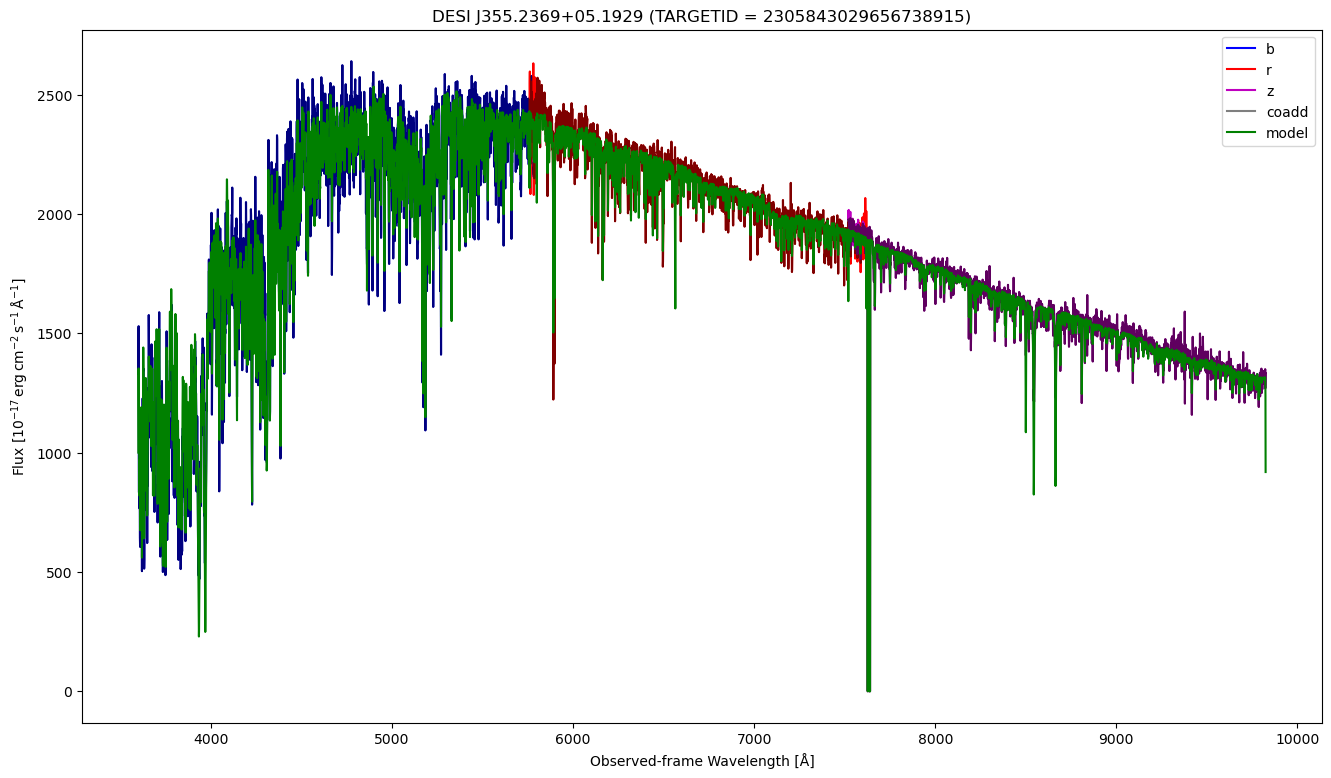

In [24]:
f = plt.figure(figsize=(16, 9), dpi=100)
ax = f.add_subplot(1, 1, 1)
p0 = ax.plot(coadd.wave['b'], coadd.flux['b'][j], 'b', label='b')
p1 = ax.plot(coadd.wave['r'], coadd.flux['r'][j], 'r', label='r')
p2 = ax.plot(coadd.wave['z'], coadd.flux['z'][j], 'm', label='z')
p3 = ax.plot(camcoadd.wave['brz'], camcoadd.flux['brz'][j], 'k', alpha=0.5, label='coadd')
plt.plot(camcoadd.wave['brz'], camcoadd.model['brz'][j], 'g', label='model')
foo = ax.set_xlabel('Observed-frame Wavelength [Å]')
foo = ax.set_ylabel(r'Flux [$10^{-17} \, \mathrm{erg} \, \mathrm{cm}^{-2} \, \mathrm{s}^{-1} \,\mathrm{\AA}^{-1}$]')
foo = ax.set_title(f"{coadd.fibermap['DESINAME'][j]} (TARGETID = {coadd.fibermap['TARGETID'][j]:d})")
l = ax.legend()

In [25]:
j += 1